# Proyecto Final — Análisis de Datos, Inteligencia de Negocios y Aprendizaje Computacional (2026-2)
## Equipo 5: Riesgo de incumplimiento en tarjetas de crédito — de los datos al tablero de decisiones

**Dataset:** *Default of Credit Card Clients* (UCI Machine Learning Repository, Yeh & Lien, 2009) — el mismo del Evento 4, ahora extendido con ETL, modelo dimensional y dashboard en Power BI.

**Integrantes:** Juan Pablo Robledo (líder) · María Camila Álvarez · Duban Guerra · Andrés Villa

**Docentes:** Carlos Jaramillo y Gustavo Macías (BI) · Daniel Nieto (Analítica de Datos) · July Galeano (Aprendizaje Computacional)

| Fase del enunciado | Sección de este notebook |
|---|---|
| 1. Recopilación y transformación (ETL) | §2 Extracción, §3 Transformación, §6 Carga |
| 2. Análisis exploratorio (EDA) | §4 |
| 3. Inteligencia de negocios (modelo de datos + dashboard) | §1.2 Reglas de negocio, §6 Modelo estrella, carpeta `powerbi/` |
| 4. Modelado predictivo supervisado | §5 |
| 5. Conclusiones y recomendaciones | §7 |

## 1. Problema de negocio

### 1.1 Contexto
Un banco de Taiwán registró para 30.000 clientes de tarjeta de crédito su cupo, datos demográficos y seis meses (abril–septiembre de 2005) de estado de pago, monto facturado y monto pagado. La variable objetivo indica si el cliente **incumplió el pago de octubre de 2005**.

**Pregunta de negocio:** ¿qué clientes tienen mayor probabilidad de incumplir el próximo mes, cuánto dinero está expuesto y qué perfiles concentran el riesgo, para que el área de cartera priorice la gestión de cobro y ajuste políticas de cupo?

**Usuarios del tablero:** gerencia de riesgo (vista general), analistas de cartera (segmentos y clientes priorizados).

### 1.2 Reglas de negocio
Estas reglas se aplican en la transformación (§3) y quedan documentadas en `docs/reglas_de_negocio.md`.

| Código | Regla |
|---|---|
| RN-01 | `EDUCATION` con códigos 0, 5, 6 (no documentados) se agrupa en 4 = "Otros"; `MARRIAGE` = 0 se agrupa en 3 = "Otros". |
| RN-02 | Estado de pago `PAY_k`: −2 = sin consumo, −1 = pagó el total, 0 = pago mínimo (revolvente), k ≥ 1 = k meses de retraso (8 = 8 o más). |
| RN-03 | Un cliente está **en mora** en un mes si su estado de pago es ≥ 1; **mora grave** si es ≥ 2. |
| RN-04 | Una factura negativa es **saldo a favor** del cliente; la exposición del mes es `max(factura, 0)`. |
| RN-05 | Utilización del cupo = factura / cupo, acotada a [−0,5; 2]. |
| RN-06 | Rangos de edad: 21–25, 26–30, 31–35, 36–40, 41–50, 51–60, 61+. Rangos de cupo (NT$): ≤50 mil, 50–100 mil, 100–200 mil, 200–500 mil, >500 mil. |
| RN-07 | Segmento de riesgo según probabilidad predicha de incumplimiento: Bajo < 20 %, Medio 20–40 %, Alto 40–60 %, Muy alto ≥ 60 %. |
| RN-08 | Pérdida esperada (NT$) = probabilidad de incumplimiento × exposición de septiembre (`max(BILL_AMT1, 0)`). |
| RN-09 | Validaciones de calidad: `ID` único, cupo > 0, edad entre 18 y 100, estados de pago entre −2 y 9, objetivo ∈ {0, 1}. Registro que no cumpla se reporta y se excluye. |

In [1]:
import warnings, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV, cross_val_predict
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import (precision_score, recall_score, f1_score, roc_auc_score, accuracy_score,
                             average_precision_score, confusion_matrix, ConfusionMatrixDisplay,
                             roc_curve, precision_recall_curve)
from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110

# Rutas: funciona si el notebook se ejecuta desde la carpeta del proyecto o desde /notebooks
BASE = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR, FIG_DIR = BASE / "data", BASE / "figuras"
STAR_DIR = DATA_DIR / "modelo_estrella"
for d in (DATA_DIR, FIG_DIR, STAR_DIR):
    d.mkdir(exist_ok=True)

def guardar(nombre):
    plt.savefig(FIG_DIR / f"{nombre}.png", bbox_inches="tight", dpi=130)

## 2. Extracción
Fuente: archivo Excel de UCI. Se busca primero en `data/`, luego en la carpeta del Evento 4 del mismo repositorio y, si no está, se descarga.

In [2]:
NOMBRE = "default of credit card clients.xls"
candidatos = [DATA_DIR / NOMBRE, BASE.parent / "evaluacion 4" / "data" / NOMBRE]
ARCHIVO = next((p for p in candidatos if p.exists()), None)
if ARCHIVO is None:
    import urllib.request, zipfile, io
    url = "https://archive.ics.uci.edu/static/public/350/default+of+credit+card+clients.zip"
    with urllib.request.urlopen(url) as r:
        zipfile.ZipFile(io.BytesIO(r.read())).extractall(DATA_DIR)
    ARCHIVO = DATA_DIR / NOMBRE

raw = pd.read_excel(ARCHIVO, header=1)      # la fila 0 contiene X1..X23
print("Fuente:", ARCHIVO.relative_to(BASE.parent))
print("Dimensiones:", raw.shape)
raw.head()

Fuente: evaluacion 4\data\default of credit card clients.xls
Dimensiones: (30000, 25)


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
0,1,20000,2,2,1,24,2,2,-1,-1,...,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,4,50000,2,2,1,37,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,5,50000,1,2,1,57,-1,0,-1,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


## 3. Transformación

### 3.1 Validaciones de calidad (RN-09) y limpieza (RN-01)

In [3]:
df = raw.rename(columns={"PAY_0": "PAY_1", "default payment next month": "DEFAULT"})
PAY  = [f"PAY_{i}" for i in range(1, 7)]
BILL = [f"BILL_AMT{i}" for i in range(1, 7)]
PAMT = [f"PAY_AMT{i}" for i in range(1, 7)]
CAT  = ["SEX", "EDUCATION", "MARRIAGE"]

validaciones = {
    "ID duplicado":               df["ID"].duplicated(),
    "Cupo <= 0":                  df["LIMIT_BAL"] <= 0,
    "Edad fuera de 18-100":       ~df["AGE"].between(18, 100),
    "Estado de pago fuera de rango": ~df[PAY].apply(lambda s: s.between(-2, 9)).all(axis=1),
    "Objetivo distinto de 0/1":   ~df["DEFAULT"].isin([0, 1]),
    "Valores nulos":              df.isna().any(axis=1),
}
reporte = pd.Series({k: int(v.sum()) for k, v in validaciones.items()}, name="registros que fallan")
display(reporte.to_frame())
invalidos = pd.concat(validaciones, axis=1).any(axis=1)
df = df[~invalidos].copy()
print(f"Registros válidos: {len(df):,}")

print("\nAntes de RN-01:")
for c in ["EDUCATION", "MARRIAGE"]:
    print(" ", c, df[c].value_counts().sort_index().to_dict())
df["EDUCATION"] = df["EDUCATION"].replace({0: 4, 5: 4, 6: 4})
df["MARRIAGE"]  = df["MARRIAGE"].replace({0: 3})

,registros que fallan
ID duplicado,0
Cupo <= 0,0
Edad fuera de 18-100,0
Estado de pago fuera de rango,0
Objetivo distinto de 0/1,0
Valores nulos,0


Registros válidos: 30,000

Antes de RN-01:
  EDUCATION {0: 14, 1: 10585, 2: 14030, 3: 4917, 4: 123, 5: 280, 6: 51}
  MARRIAGE {0: 54, 1: 13659, 2: 15964, 3: 323}


### 3.2 Variables derivadas (RN-03 a RN-06)
Calculadas fila a fila, por lo que no aprenden nada del conjunto y no generan fuga de información hacia el modelo.

In [4]:
ETIQ = {"SEX": {1: "Hombre", 2: "Mujer"},
        "EDUCATION": {1: "Posgrado", 2: "Universidad", 3: "Secundaria", 4: "Otros"},
        "MARRIAGE": {1: "Casado", 2: "Soltero", 3: "Otros"}}

def crear_variables(d):
    d = d.copy()
    d["n_meses_mora"]   = (d[PAY] >= 1).sum(axis=1)                       # RN-03
    d["max_mora"]       = d[PAY].max(axis=1).clip(lower=0)
    d["meses_inactivo"] = (d[PAY] == -2).sum(axis=1)
    util = d[BILL].div(d["LIMIT_BAL"], axis=0)                             # RN-05
    d["util_media"] = util.mean(axis=1).clip(-0.5, 2)
    d["util_max"]   = util.max(axis=1).clip(-0.5, 2)
    pagado = d[PAMT[:5]].sum(axis=1)                                       # PAY_AMT_k paga BILL_AMT_{k+1}
    debido = d[BILL[1:]].clip(lower=0).sum(axis=1)
    d["ratio_pago"] = np.where(debido > 0, pagado / debido.replace(0, np.nan), 1.0)
    d["ratio_pago"] = d["ratio_pago"].clip(0, 1)
    d["tendencia_deuda"] = ((d["BILL_AMT1"] - d["BILL_AMT6"]) / d["LIMIT_BAL"]).clip(-2, 2)
    return d

df = crear_variables(df)
NUEVAS = ["n_meses_mora", "max_mora", "meses_inactivo", "util_media", "util_max", "ratio_pago", "tendencia_deuda"]

# RN-06: rangos para el análisis y el tablero
df["rango_edad"] = pd.cut(df["AGE"], [20, 25, 30, 35, 40, 50, 60, 120],
                          labels=["21-25", "26-30", "31-35", "36-40", "41-50", "51-60", "61+"]).astype(str)
df["rango_cupo"] = pd.cut(df["LIMIT_BAL"], [0, 50_000, 100_000, 200_000, 500_000, np.inf],
                          labels=["<=50 mil", "50-100 mil", "100-200 mil", "200-500 mil", ">500 mil"]).astype(str)
df[NUEVAS + ["rango_edad", "rango_cupo"]].head()

,n_meses_mora,max_mora,meses_inactivo,util_media,util_max,ratio_pago,tendencia_deuda,rango_edad,rango_cupo
0,2,2,2,0.064200,0.195650,0.181746,0.195650,21-25,<=50 mil
1,2,2,0,0.023718,0.028792,0.208406,-0.004825,26-30,100-200 mil
2,0,0,0,0.188246,0.324878,0.083105,0.152111,31-35,50-100 mil
3,0,0,0,0.771113,0.985820,0.040077,0.348860,36-40,<=50 mil
4,0,0,0,0.364463,0.716700,0.579516,-0.210280,51-60,<=50 mil


### 3.3 De formato ancho a formato largo
Los seis meses vienen como columnas (`PAY_1..6`, `BILL_AMT1..6`, `PAY_AMT1..6`). Para el modelo dimensional se pasa a **una fila por cliente y mes**, que es el grano de la tabla de hechos del estado de cuenta. El índice 1 corresponde a septiembre de 2005 y el 6 a abril de 2005.

In [5]:
MESES = {1: "2005-09", 2: "2005-08", 3: "2005-07", 4: "2005-06", 5: "2005-05", 6: "2005-04"}
partes = []
for k, mes in MESES.items():
    partes.append(pd.DataFrame({
        "id_cliente": df["ID"].values,
        "id_mes": int(mes.replace("-", "")),
        "id_estado_pago": df[f"PAY_{k}"].clip(upper=8).values,             # RN-02
        "monto_facturado": df[f"BILL_AMT{k}"].values,
        "monto_pagado": df[f"PAY_AMT{k}"].values,
        "cupo": df["LIMIT_BAL"].values,
    }))
largo = pd.concat(partes, ignore_index=True)
largo["exposicion"]  = largo["monto_facturado"].clip(lower=0)              # RN-04
largo["saldo_a_favor"] = (largo["monto_facturado"] < 0).astype(int)
largo["utilizacion"] = (largo["monto_facturado"] / largo["cupo"]).clip(-0.5, 2).round(4)   # RN-05
largo["en_mora"]     = (largo["id_estado_pago"] >= 1).astype(int)          # RN-03
largo["mora_grave"]  = (largo["id_estado_pago"] >= 2).astype(int)
largo = largo.drop(columns="cupo")
print("Filas formato largo:", f"{len(largo):,}", "(= clientes × 6 meses)")
largo.head()

Filas formato largo: 180,000 (= clientes × 6 meses)


,id_cliente,id_mes,id_estado_pago,monto_facturado,monto_pagado,exposicion,saldo_a_favor,utilizacion,en_mora,mora_grave
0,1,200509,2,3913,0,3913,0,0.1956,1,1
1,2,200509,-1,2682,0,2682,0,0.0223,0,0
2,3,200509,0,29239,1518,29239,0,0.3249,0,0
3,4,200509,0,46990,2000,46990,0,0.9398,0,0
4,5,200509,-1,8617,2000,8617,0,0.1723,0,0


## 4. Análisis exploratorio (EDA)
El EDA detallado de variables individuales está en el Evento 4. Aquí nos centramos en lo que aporta el formato largo y en las preguntas que responderá el tablero.

### 4.1 Variable objetivo

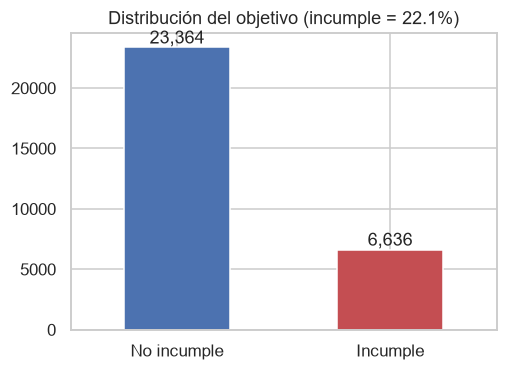

In [6]:
tasa = df["DEFAULT"].mean()
fig, ax = plt.subplots(figsize=(5, 3.5))
df["DEFAULT"].map({0: "No incumple", 1: "Incumple"}).value_counts().plot.bar(ax=ax, color=["#4C72B0", "#C44E52"])
ax.set_title(f"Distribución del objetivo (incumple = {tasa:.1%})"); ax.set_xlabel(""); ax.tick_params(axis="x", rotation=0)
for p in ax.patches:
    ax.annotate(f"{int(p.get_height()):,}", (p.get_x() + p.get_width()/2, p.get_height()), ha="center", va="bottom")
guardar("01_objetivo"); plt.show()

### 4.2 Tendencias mensuales de la cartera (abril–septiembre 2005)

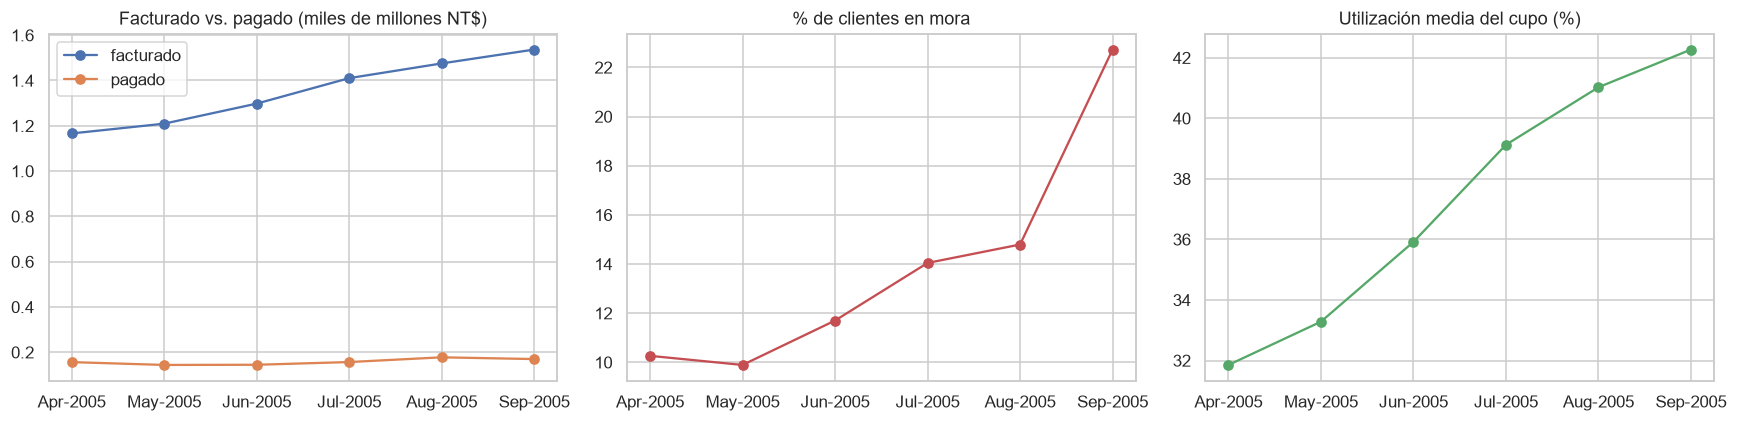

,facturado,pagado,pct_mora,utilizacion
id_mes,,,,
Apr-2005,1166152812,156465077,0.103,0.319
May-2005,1209342029,143981629,0.099,0.333
Jun-2005,1297888469,144782306,0.117,0.359
Jul-2005,1410394644,156770445,0.140,0.391
Aug-2005,1475372255,177634905,0.148,0.410
Sep-2005,1536699927,169907415,0.227,0.423


In [7]:
mensual = largo.groupby("id_mes").agg(facturado=("monto_facturado", "sum"), pagado=("monto_pagado", "sum"),
                                      pct_mora=("en_mora", "mean"), utilizacion=("utilizacion", "mean"))
mensual.index = pd.to_datetime(mensual.index.astype(str), format="%Y%m").strftime("%b-%Y")
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
(mensual[["facturado", "pagado"]] / 1e9).plot(marker="o", ax=axes[0]); axes[0].set_title("Facturado vs. pagado (miles de millones NT$)")
(mensual["pct_mora"] * 100).plot(marker="o", color="#C44E52", ax=axes[1]); axes[1].set_title("% de clientes en mora")
(mensual["utilizacion"] * 100).plot(marker="o", color="#55A868", ax=axes[2]); axes[2].set_title("Utilización media del cupo (%)")
for a in axes: a.set_xlabel("")
plt.tight_layout(); guardar("02_tendencias_mensuales"); plt.show()
mensual.round(3)

### 4.3 Perfiles: ¿dónde se concentra el incumplimiento?

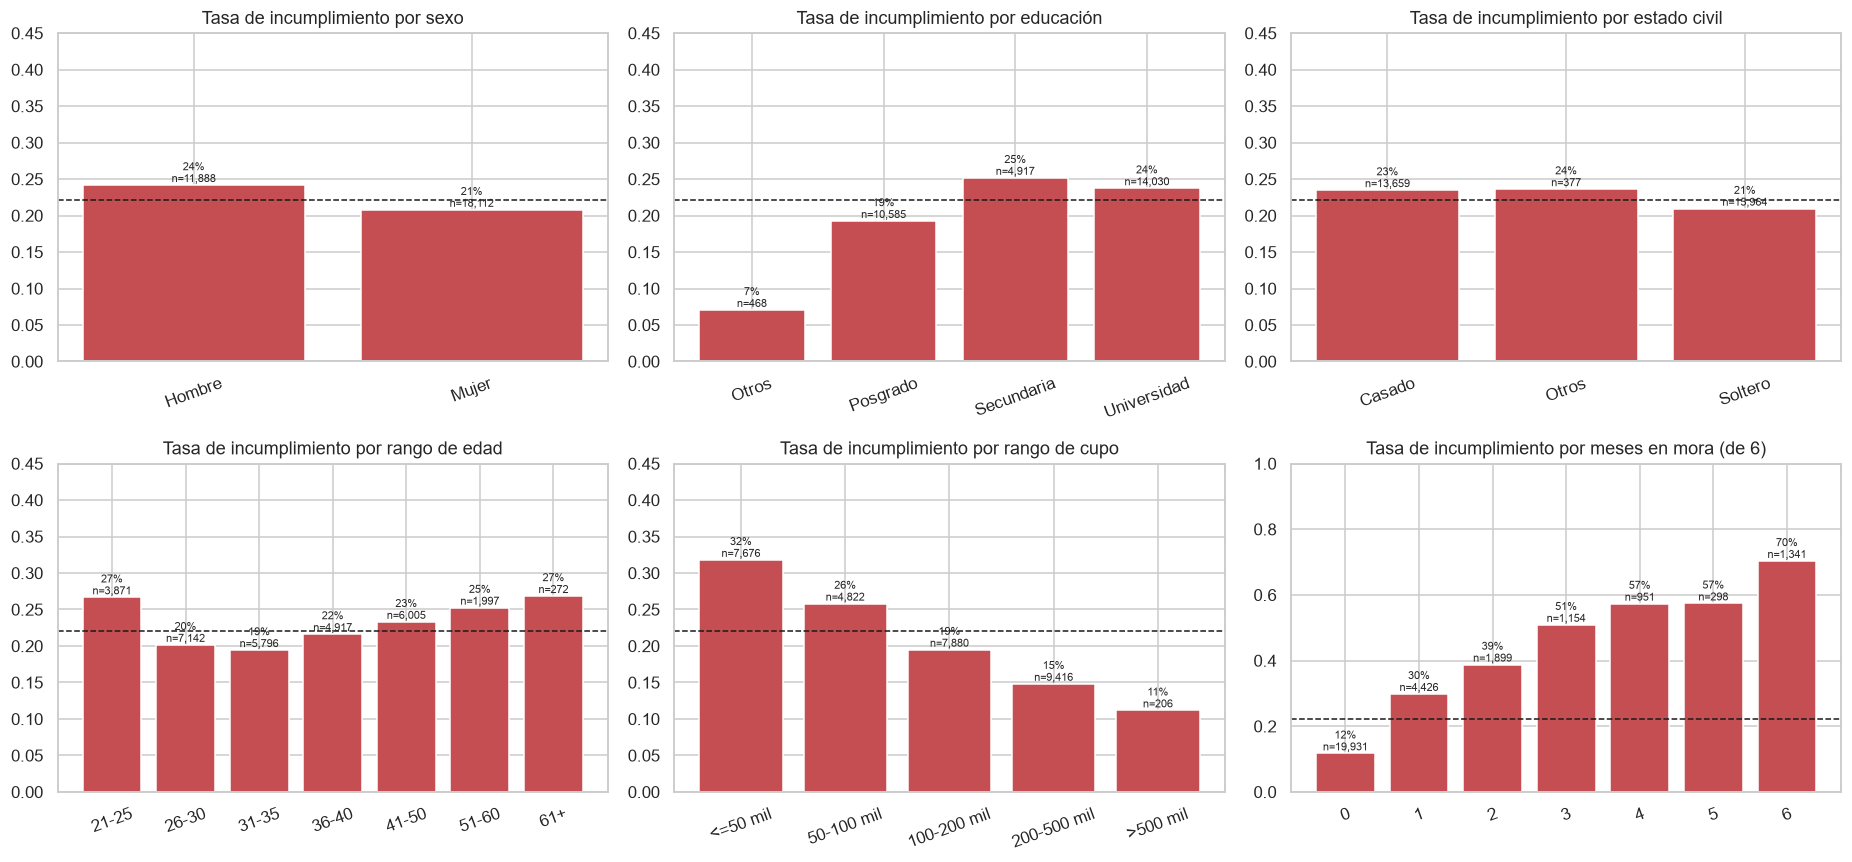

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(17, 8))
dims = [("SEX", "Sexo"), ("EDUCATION", "Educación"), ("MARRIAGE", "Estado civil"),
        ("rango_edad", "Rango de edad"), ("rango_cupo", "Rango de cupo"), ("n_meses_mora", "Meses en mora (de 6)")]
ordenes = {"rango_cupo": ["<=50 mil", "50-100 mil", "100-200 mil", "200-500 mil", ">500 mil"]}
for ax, (c, titulo) in zip(axes.ravel(), dims):
    clave = df[c].map(ETIQ[c]) if c in ETIQ else df[c]
    t = df.groupby(clave)["DEFAULT"].agg(["mean", "size"])
    if c in ordenes: t = t.reindex(ordenes[c])
    ax.bar(t.index.astype(str), t["mean"], color="#C44E52")
    ax.axhline(tasa, ls="--", c="k", lw=1)
    for i, (m, n) in enumerate(t.values):
        ax.text(i, m, f"{m:.0%}\nn={int(n):,}", ha="center", va="bottom", fontsize=7)
    ax.set_title(f"Tasa de incumplimiento por {titulo.lower()}"); ax.set_ylim(0, 1 if c == "n_meses_mora" else .45)
    ax.tick_params(axis="x", rotation=20)
plt.tight_layout(); guardar("03_perfiles"); plt.show()

### 4.4 Correlaciones con el incumplimiento

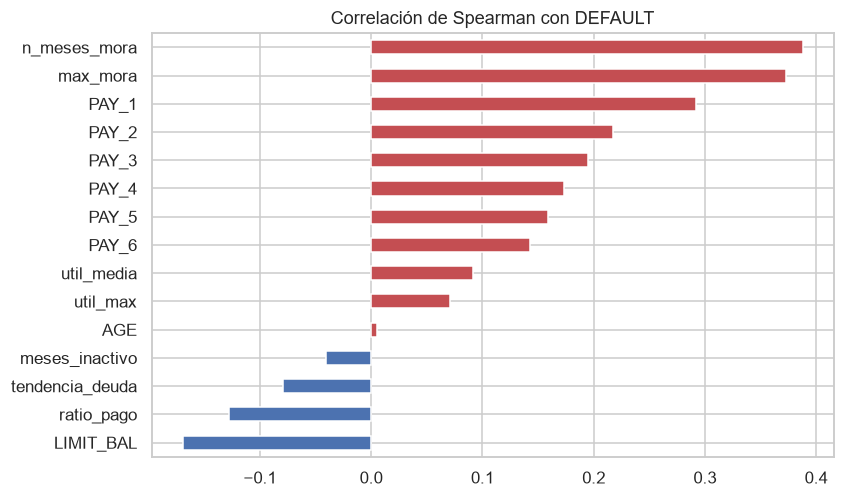

In [9]:
corr = df[["LIMIT_BAL", "AGE"] + PAY + NUEVAS + ["DEFAULT"]].corr(method="spearman")["DEFAULT"].drop("DEFAULT")
fig, ax = plt.subplots(figsize=(8, 5))
corr.sort_values().plot.barh(ax=ax, color=np.where(corr.sort_values() > 0, "#C44E52", "#4C72B0"))
ax.set_title("Correlación de Spearman con DEFAULT"); guardar("04_correlaciones"); plt.show()

**Lectura del EDA** *(completar/ajustar por el equipo)*
- ≈22 % de los clientes incumple: desbalance moderado, por lo que no basta con *accuracy*.
- El historial de pagos es la señal más fuerte: la tasa crece casi monótonamente con los meses en mora.
- Cupos bajos y alta utilización se asocian con mayor incumplimiento; las diferencias demográficas son pequeñas.